# Interpolation to stations: ICON-CH2 wind gusts

This example illustrates {func}`~grid_process.grid_interp.interp2poi` with three methods:

- `linear`: linear interpolation on the triangulation of the source grid points;
- `idw`: inverse distance weighting of the `k` nearest grid points, with weights `d^(-weight_power)`;
- `nearest_alt`: among the grid points within `r_search` grid spacings, the one with the most similar
  altitude. This suits wind, which depends strongly on the exposure of the site.

The hourly maximum 10 m wind gust (`VMAX_10M`) of the ICON-CH2 control forecast, on its native
unstructured grid (about 2 km), is interpolated to the MeteoSwiss automatic weather stations measuring
gusts, and compared with the observed hourly maximum gust.

*Data: MeteoSwiss open data, CC BY 4.0, source: MeteoSwiss. Country borders: Natural Earth.*

In [1]:
import datetime as dt
import os
import time
import timeit
from concurrent.futures import ThreadPoolExecutor

import pyproj  # noqa: F401  # import before earthkit.data to avoid a crash at exit (earthkit-data#1202)
import eccodes_cosmo_resources

# ICON GRIB files need the COSMO definitions of ecCodes
os.environ["ECCODES_DEFINITION_PATH"] = str(eccodes_cosmo_resources.get_definitions_path())
os.environ["ECCODES_VERSION_CHECK_OFF"] = "1"

import cartopy.io.shapereader as shpreader
import earthkit.data as ekd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

import grid_process.grid_interp as gri
import grid_process.timeseries as tms

METHODS = {
    "linear": {"method": "linear"},
    "idw": {"method": "idw", "k": 4, "weight_power": 2},
    "nearest_alt": {"method": "nearest_alt", "r_search": 1.7},
}
LEAD_H = 12  # lead time [h] shown on the maps, short enough to be covered by observations

## Source data

ICON-CH2 runs stay on the MeteoSwiss open data portal for 24 hours. We take the oldest run, so that
observations already cover the first lead times, and download the control member for all 121 lead
times. The files cover the full model domain, as no spatial subset can be requested. `nearest_alt`
needs the model orography `HSURF`, provided with the grid coordinates in the horizontal constants file.

In [2]:
COLLECTION = "ogd-forecasting-icon-ch2"


def oldest_run(variable: str, margin: dt.timedelta = dt.timedelta(minutes=30)) -> str:
    """Oldest run whose first lead time (uploaded, hence deleted, first) is still available."""
    response = requests.post(
        "https://data.geo.admin.ch/api/stac/v1/search",
        json={
            "collections": [f"ch.meteoschweiz.{COLLECTION}"],
            "forecast:variable": variable,
            "forecast:perturbed": False,
            "forecast:horizon": "P0DT00H00M00S",
            "sortby": [{"field": "properties.datetime", "direction": "asc"}],
        },
        timeout=30,
    )
    now = dt.datetime.now(dt.timezone.utc)
    for item in response.json()["features"]:
        if dt.datetime.fromisoformat(item["properties"]["expires"]) > now + margin:
            return item["properties"]["forecast:reference_datetime"]
    raise RuntimeError("No run found on the open data portal")


ref_time = oldest_run("VMAX_10M")
print(f"ICON-CH2 run: {ref_time}")

ds = ekd.from_source(
    "meteoswiss-opendata",
    collection=COLLECTION,
    variable="VMAX_10M",
    ref_time=ref_time,
    perturbed=False,
    lead_time=[f"P0DT{h}H" for h in range(121)],
).to_xarray(time_dims=["forecast_reference_time", "step"], squeeze=False)
ds = ds.squeeze(["member", "level", "level_type"], drop=True).rename_dims(values="cell").astype("float32")

constants = ekd.from_source("meteoswiss-opendata-constants", collection=COLLECTION, asset="horizontal")
hsurf = constants.to_fieldlist().sel({"parameter.variable": "HSURF"})[0].to_numpy()
ds = ds.assign_coords(HSURF=("cell", hsurf.astype("float32"))).load()
ds = tms.setindex_validtime(ds)  # forecast_reference_time and step -> time
ds

ICON-CH2 run: 2026-10-28T00:00:00Z


<multiple>: 0.00B [00:00, ?B/s]

<multiple>: 1.08MB [00:00, 5.37MB/s]

<multiple>: 2.17MB [00:00, 5.02MB/s]

<multiple>: 3.25MB [00:00, 5.75MB/s]

...

<multiple>: 65.0MB [00:14, 4.51MB/s]

<multiple>: 65.5MB [00:14, 4.27MB/s]

horizontal_constants_icon-ch2-eps.grib2?AWSAccessKeyId=13GC1T4NT2CY1N0L92YC&Signature=hAqy%2FeaEBFpETlvpDVkQCFcD7Do%3D&Expires=1795899197: 0.00B [00:00, ?B/s]

horizontal_constants_icon-ch2-eps.grib2?AWSAccessKeyId=13GC1T4NT2CY1N0L92YC&Signature=hAqy%2FeaEBFpETlvpDVkQCFcD7Do%3D&Expires=1795899197: 1.00MB [00:00, 7.06MB/s]

<xarray.Dataset> Size: 143MB
Dimensions:                  (time: 121, cell: 283876)
Coordinates:
  * time                     (time) datetime64[us] 968B 2026-10-28 ... 2026-1...
    forecast_reference_time  (time) datetime64[us] 968B 2026-10-28 ... 2026-1...
    latitude                 (cell) float64 2MB 46.97 46.98 ... 50.06 50.05
    longitude                (cell) float64 2MB -0.1542 -0.1638 ... 12.83 12.81
    HSURF                    (cell) float32 1MB 94.11 87.99 ... 626.5 682.7
Dimensions without coordinates: cell
Data variables:
    VMAX_10M                 (time, cell) float32 137MB 0.0 0.0 ... 3.398 3.741
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Stations and observations

The stations measuring gusts are selected from the data inventory. Their metadata provide the
coordinates and the altitude (`height_masl`) used by `nearest_alt`; the `name` column becomes the `poi`
coordinate of the output. The observed hourly maximum gust (`fkl010h1`, 1 s peak) and `VMAX_10M` both
refer to the hour ending at the valid time.

In [3]:
SMN_URL = "https://data.geo.admin.ch/ch.meteoschweiz.ogd-smn"
GUST = "fkl010h1"

inventory = pd.read_csv(f"{SMN_URL}/ogd-smn_meta_datainventory.csv", sep=";", encoding="cp1252")
gust_stations = inventory.loc[(inventory.parameter_shortname == GUST) & inventory.data_till.isna(), "station_abbr"]

meta = pd.read_csv(f"{SMN_URL}/ogd-smn_meta_stations.csv", sep=";", encoding="cp1252")
meta = meta.rename(columns={"station_abbr": "name", "station_height_masl": "height_masl"})
meta = meta[meta["name"].isin(gust_stations)]
pois = gpd.GeoDataFrame(
    meta[["name", "station_name", "height_masl"]],
    geometry=gpd.points_from_xy(meta["station_coordinates_lv95_east"], meta["station_coordinates_lv95_north"]),
    crs="EPSG:2056",
).set_index("name", drop=False)


def read_smn(abbr: str, granularity: str, periods: tuple[str, ...] = ("recent", "now")) -> pd.DataFrame:
    """Read station data files (granularity 't': 10 min, 'h': hourly); timestamps are in UTC."""
    frames = [
        pd.read_csv(
            f"{SMN_URL}/{abbr.lower()}/ogd-smn_{abbr.lower()}_{granularity}_{period}.csv", sep=";", encoding="cp1252"
        )
        for period in periods
    ]
    df = pd.concat(frames)
    df["time"] = pd.to_datetime(df["reference_timestamp"], format="%d.%m.%Y %H:%M")
    return df.drop_duplicates("time").set_index("time").sort_index()


valid_time = ds.time.values[LEAD_H]
# the "now" files start today at 00 UTC, older timestamps are in the "recent" files
periods = ("now",) if valid_time >= np.datetime64(dt.datetime.now(dt.timezone.utc).date()) else ("recent",)


def observed_gust(abbr: str) -> float:
    try:
        return read_smn(abbr, "h", periods)[GUST].get(valid_time, np.nan)
    except OSError:  # missing file
        return np.nan


with ThreadPoolExecutor(max_workers=8) as executor:
    pois["observation"] = list(executor.map(observed_gust, pois["name"]))
print(f"{len(pois)} stations, {pois.observation.notna().sum()} with an observation at {valid_time}")

151 stations, 151 with an observation at 2026-10-28T12:00:00.000000


## Interpolation

Each method is called once on all lead times. The duration of this first call is kept for the
benchmark below.

In [4]:
results, first_call = {}, {}
for label, kwargs in METHODS.items():
    t0 = time.perf_counter()
    results[label] = gri.interp2poi(ds, pois, **kwargs)
    first_call[label] = time.perf_counter() - t0
    pois[label] = results[label]["VMAX_10M"].sel(time=valid_time).to_series()
results["nearest_alt"]

<xarray.Dataset> Size: 77kB
Dimensions:                  (poi: 151, time: 121)
Coordinates:
  * poi                      (poi) <U3 2kB 'ABO' 'AEG' 'AIG' ... 'WYN' 'ZER'
  * time                     (time) datetime64[us] 968B 2026-10-28 ... 2026-1...
    forecast_reference_time  (time) datetime64[us] 968B 2026-10-28 ... 2026-1...
Data variables:
    VMAX_10M                 (poi, time) float32 73kB 1.588 1.588 ... 2.444
Attributes:
    institution:  ECMWF

## Visual comparison

Wind gusts at each station for the lead time `LEAD_H`, on a common colour scale.

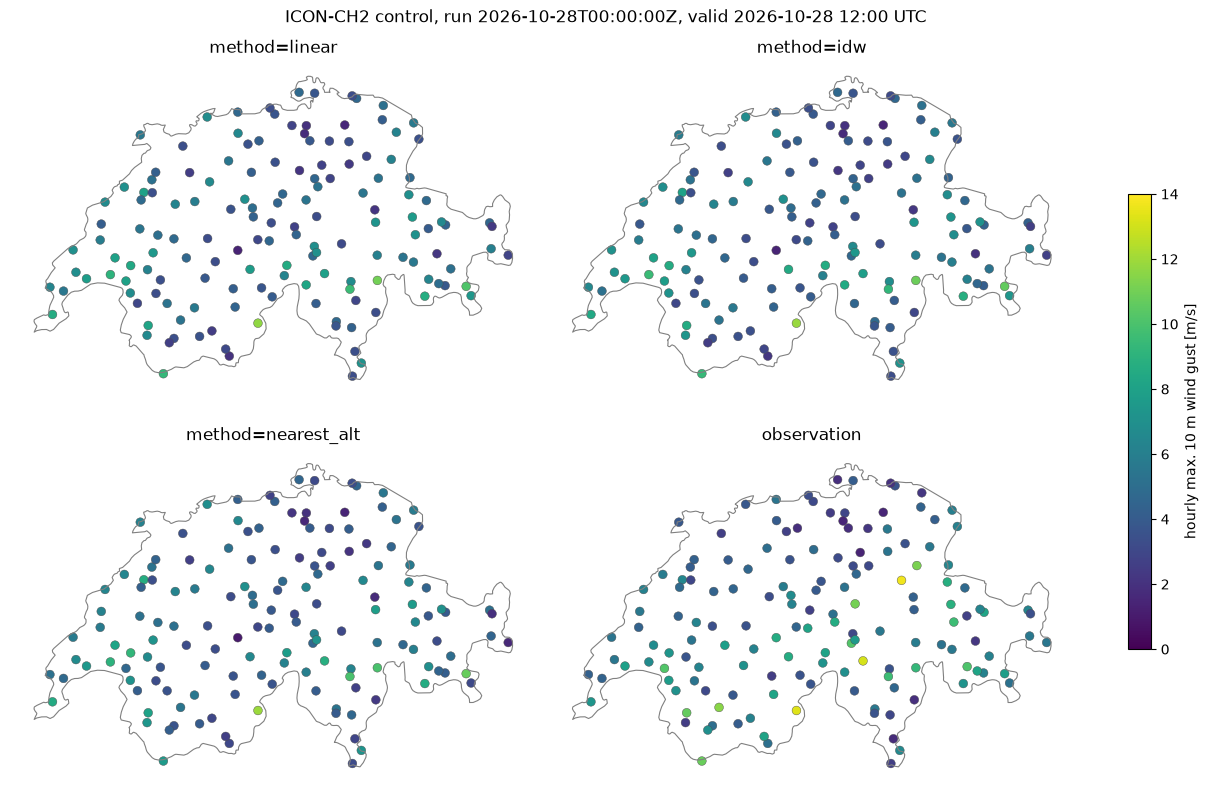

In [5]:
borders = gpd.read_file(shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries"))
switzerland = borders[borders["ADMIN"] == "Switzerland"].set_crs("EPSG:4326").to_crs("EPSG:2056")

panels = [*METHODS, "observation"]
vmax = np.ceil(pois[panels].max().max())
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for ax, column in zip(axes.flat, panels):
    switzerland.boundary.plot(ax=ax, color="0.5", linewidth=0.8)
    pois.dropna(subset=column).plot(
        column=column, ax=ax, cmap="viridis", vmin=0, vmax=vmax, markersize=40, edgecolor="0.3", linewidth=0.3
    )
    ax.set_title(column if column == "observation" else f"method={column}")
    ax.set_axis_off()
fig.colorbar(axes[0, 0].collections[-1], ax=axes, shrink=0.6, label="hourly max. 10 m wind gust [m/s]")
fig.suptitle(f"ICON-CH2 control, run {ref_time}, valid {pd.Timestamp(valid_time):%Y-%m-%d %H:%M} UTC")
plt.show()

## Performance benchmark

The first call includes building the neighbour search structures (or the triangulation for `linear`).
`grid_process` caches the neighbour search, so subsequent calls on the same grid and stations (e.g. for
other variables or runs) are faster: their runtime is the mean ± standard deviation over 5 repetitions. The `try_reg` option has no effect here, since ICON-CH2 is an unstructured grid.

In [6]:
def benchmark(func, data, target, methods: dict, first_call: dict, repeat: int = 5) -> pd.DataFrame:
    rows = []
    for label, kwargs in methods.items():
        warm = np.array(timeit.repeat(lambda: func(data, target, **kwargs), number=1, repeat=repeat))
        rows.append(
            {
                "method": label,
                "kwargs": ", ".join(f"{k}={v}" for k, v in kwargs.items() if k != "method"),
                "first call [s]": first_call[label],
                "subsequent calls [s]": f"{warm.mean():.3f} ± {warm.std():.3f}",
            }
        )
    return pd.DataFrame(rows).set_index("method").round(3)


print(f"{ds.cell.size} grid cells × {ds.time.size} lead times -> {len(pois)} stations")
benchmark(gri.interp2poi, ds, pois, METHODS, first_call)

283876 grid cells × 121 lead times -> 151 stations


,kwargs,first call [s],subsequent calls [s]
method,,,
linear,,0.178,0.171 ± 0.001
idw,"k=4, weight_power=2",0.022,0.015 ± 0.003
nearest_alt,r_search=1.7,0.036,0.013 ± 0.000


## Takeaways

- At the resolution of ICON-CH2 (about 2 km) the three methods give similar gusts at most stations. The
  differences between methods are usually smaller than the differences to the observations.
- `linear` and `idw` average neighbouring grid points and give smooth values. `nearest_alt` takes a
  single grid point selected for its altitude, which may be more or less exposed than its horizontal
  neighbours. Its values therefore differ most at mountain stations.
- A 1 s peak gust measured at one site is very local: comparing stations at a single time is a
  qualitative check, not a verification.
- Once the neighbour search is cached, `idw` and `nearest_alt` are cheap. `linear` triangulates the
  unstructured grid at every call and is the slowest method.